# Landscape of development of XGBoost

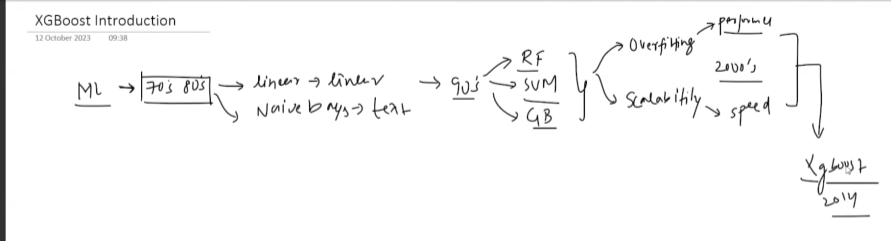

- On initial days (70's/80's) the ML algorithms that we available (like Linear Regression, Logistic Regression, etc.) worked well only on a particular type of data (linear data).

- So, the researchers started developing new algorithms that could work on a variety of data types. This led to the development of Gradient Boosting, Random Forests, Support Vector Machines (SVM) in the 90's.

- But still this algo used to struggle with:
    1. Overfitting
    2. Worked slow on large datasets

- In 2014, XGBoost was developed by Tianqi Chen and it was a game changer in the field of ML and it solved both the above problem. It was faster and more accurate than the previous algorithms.

 **NOTE**: <text style="color:orange">XGBoost is not an algorithm, but a **library** which is built on top of the Gradient Boosting algorithm.</text>

 - So XGBoost is basically an implementation of Gradient Boosting algorithm with some additional optimizations and features that make it faster and more accurate than the original Gradient Boosting algorithm.

# History of XGBoost

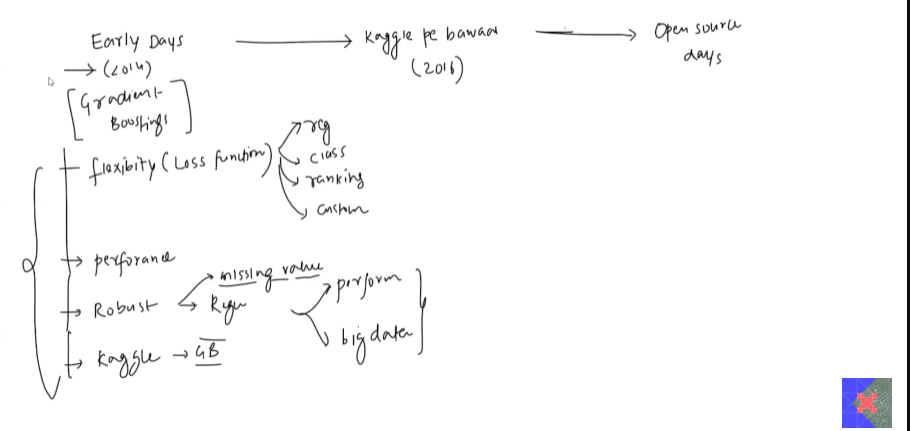

- In 2014, Tianqi Chen developed XGBoost as part of his PhD research at the University of Washington. 

- He picked Gradient Boosting algorithm as the base algorithm because of the following reasons:
    1. Flexible: It can be used for varities of problems like regression, classification, ranking, etc. because all we need is a differentiable loss function.
    2. Performance: It is known to perform well on a variety of datasets and it is also known to be robust to overfitting.
    3. Robustness: It is known to be robust to outliers and noise in the data and it can also handle missing values in the data.
    4. Kaggle Competitions: It has been used to win many Kaggle competitions and it is also known to be the most popular algorithm in Kaggle competitions.

<hr>

- In 2016 he participated in Higgs Boson Machine Learning Challenge and won the 1st place in the competition using XGBoost. This was a big achievement for him and it also brought a lot of attention to XGBoost.

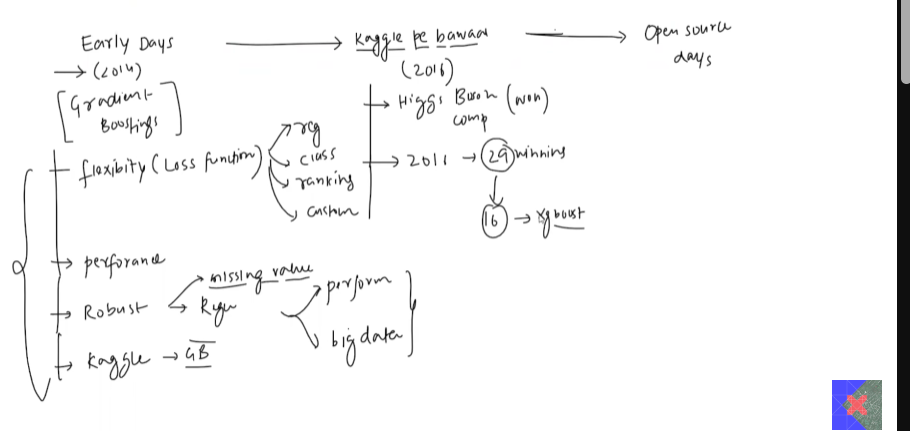

- Seeing the success of XGBoost, he decided to open source the library and it was released on GitHub in 2016. Since then, it has been widely adopted by the ML community and it is now one of the most popular ML libraries in the world.

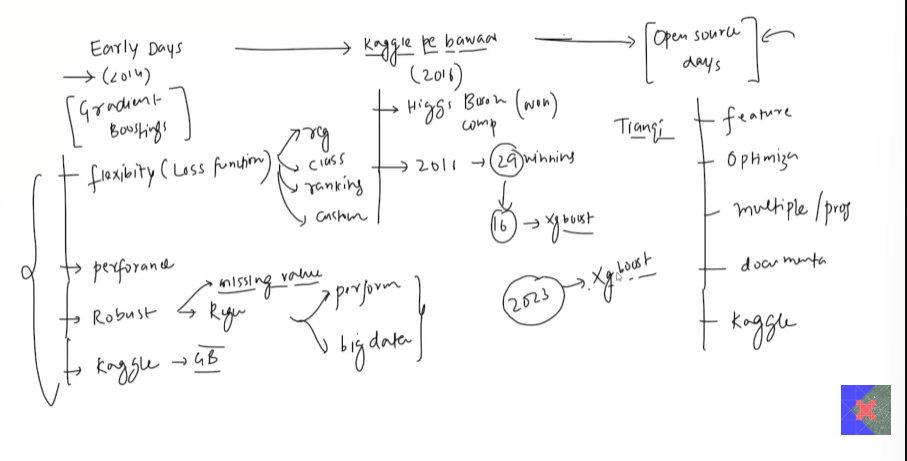

# Features of XGBoost

- While building XGBoost, Tianqi Chen had 3 main goals in mind:
    1. Performance: It should not have overfitting problems, robust ho..
    2. Speed: It should be faster than the existing algorithms and it should be able to handle large datasets.
    3. Flexibility: He wanted that everyone should be able to use it easily, flexibility in terms of programming language and platform both

## 1. Flexibility

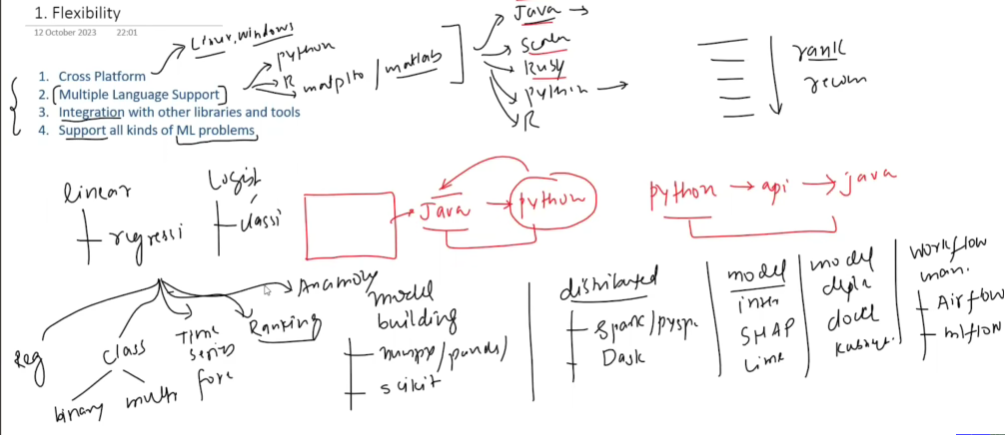

## 2. Speed
- 6 Software Engineering Optimizations were made to make XGBoost faster than the existing algorithms. They are:

### 2.1. Parallel Processing:

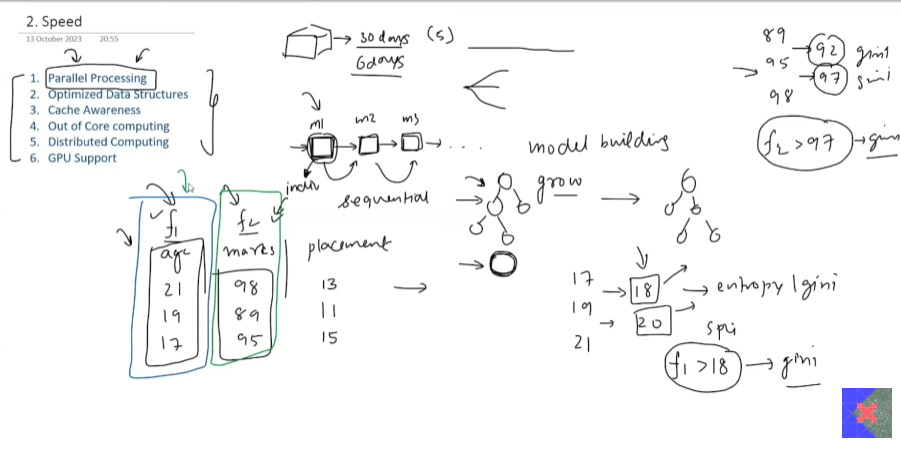

- The parallel processing is done at the level of the decision tree building process. As in the picture above, for 2 features f1, we can calculate the best split for both features in parallel and then choose the best split among them. This is done for all the features in the dataset. 

- Set `n_jobs=-1` in the `XGBRegressor` or `XGBClassifier` to use all the available cores in your machine for parallel processing.

- In genereal if we didn't do parallel processing, then for each feature we would have to calculate the best split one by one and this would take a lot of time. But with parallel processing, we can calculate the best split for all the features in parallel and this reduces the time taken to build the decision tree.

- NOTE: The parallel processing is done at the level of the decision tree building process and not at the level of the boosting process. As Boosting is a sequential process, we cannot parallelize it.

### 2.2. Use of Optimized Data Structure:

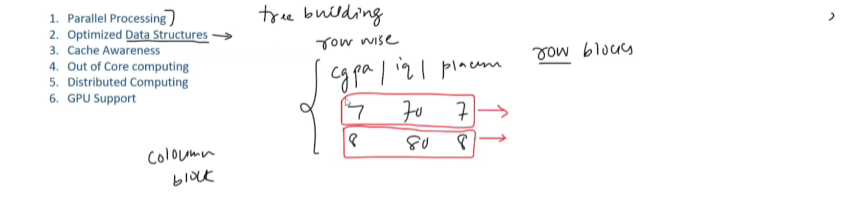

- Generally we store data row wise in a 2D array or a dataframe
- But in XGBoost, we use **column block structure** to store the data.

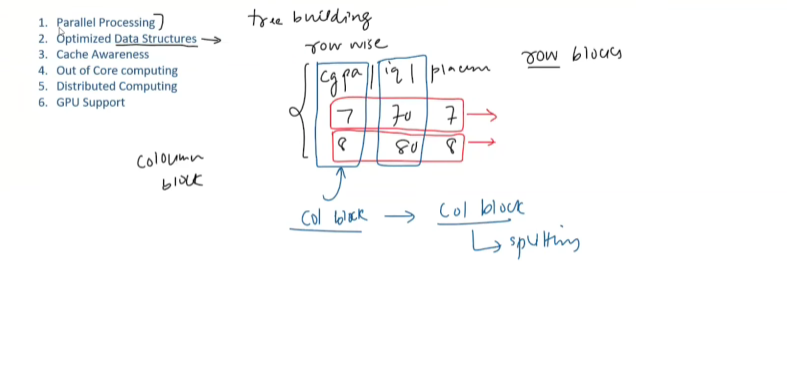

- This is because, in decision tree building process, we need to calculate the best split for each feature and this requires us to access the data column wise. So, by storing the data in column block structure, we can access the data more efficiently and this reduces the time taken to build the decision tree.

- It is the reason why we can do parallel processing in XGBoost, as we can access the data for each feature in parallel and calculate the best split for each feature in parallel.

### 2.3 Cache Awareness:

- It is a technique used to make the algorithm more efficient by making use of the CPU cache. The CPU cache is a small amount of memory that is used to store frequently accessed data. By making the algorithm cache aware, we can reduce the number of times we need to access the main memory and this reduces the time taken to build the decision tree.

- XGBoost stores Histogram of the features in the CPU cache and this makes the algorithm more efficient. The histogram is used to calculate the best split for each feature and by storing it in the CPU cache, we can access it more efficiently.

### 2.4. Out of Core Computing:

- Suppose our PC have 8GB of RAM and we have a dataset of 10GB, then we cannot load the entire dataset into the memory and this will lead to memory error. So, in such cases, we can use out of core computing to handle such large datasets.

- In out of core computing, we load the data in chunks and process it in batches sequentially. This way, we can handle large datasets that do not fit into the memory.

- Set `tree_method='hist'` in the `XGBRegressor` or `XGBClassifier` to use out of core computing, it also uses cache awareness

### 2.5 Distributed Computing:

- It is the method of distributing the computation across multiple machines/nodes . And all the nodes does the computation in parallel and this reduces the time taken to build the decision tree.

- So if you have multiple machines in a cluster, then you can use distributed computing to build the decision tree faster.

- It is better than Out of Core Computing, as in Out of Core Computing, we are limited by the memory of a single machine so it does sequential processing, but in Distributed Computing, we can use multiple machines and this reduces the time taken to build the decision tree.

- We can use external libraries like Dask or Kubernetes to implement distributed computing in XGBoost.

### 2.6 GPU Support:

- XGBoost also supports GPU acceleration and this makes the algorithm even faster. The GPU is a specialized hardware that is designed to perform parallel computations and it can perform computations much faster than the CPU.

- And as in XGBoost, we can do parallel processing at the level of the decision tree building process, so we can use the GPU to perform these computations in parallel and this reduces the time taken to build the decision tree.

- Set `tree_method='gpu_hist'` in the `XGBRegressor` or `XGBClassifier` to use GPU acceleration.

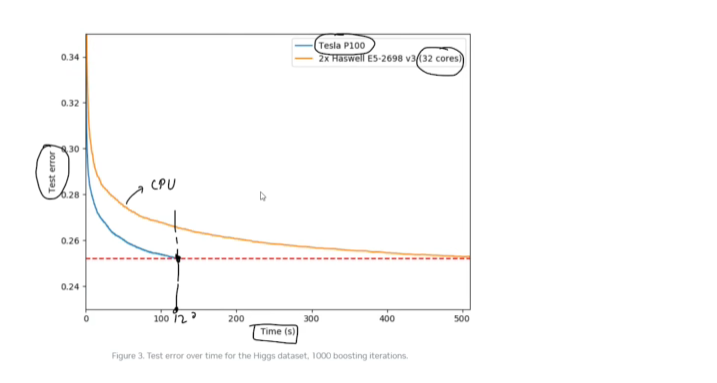

## 3. Performance

- Here we will see how 5 ML concepts were used to improve the performance of XGBoost

### 3.1. Regularization:

- **Traditional Gradient Boosting:** Primarily controls overfitting through:
    1. Shrinkage (learning rate).
    2. Tree construction constraints (max_depth, max_leaf_nodes, etc.).

- **XGBoost:** In addition to the above techniques, introduces an explicit regularization term in its objective function to penalize model complexity.

    - γ (gamma): Penalizes the addition of leaf nodes.
    - λ (lambda): Applies L2 regularization to leaf weights.
    - This discourages overly complex trees and helps prevent overfitting.

**Note:**
- Traditional Gradient Boosting can also incorporate an explicit regularization term into its objective function; it is not fundamentally restricted to learning rate and tree-construction constraints.
- However, XGBoost explicitly incorporates regularization into its standard objective function and uses it during tree construction (split evaluation and leaf-weight calculation).
- Thus, XGBoost makes explicit regularization an integral part of its optimization framework.

### 3.2. Handling Missing Values

- XGBoost uses a unique approach to handle missing values in the dataset. It automatically learns the best direction to handle missing values during training using **Sparsity aware split finding**

### 3.3. Sparsity Aware Split Finding 

- Sparsity means having a lot of missing values/zero values in the dataset. In such cases, we can use sparsity aware split finding to handle such datasets.

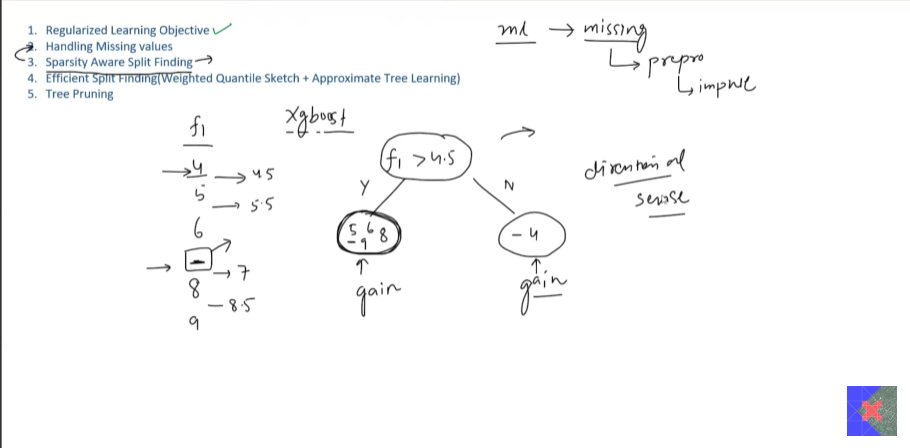

- So, as in the above pic you can see, XGBoost tests the data point with missing value in both the left and right child of the split node and then it assigns the data point to the child node that gives the best split (maximizing the gain). This way, we can handle missing values in the dataset and this improves the performance of the algorithm.

### 3.4. Efficient Split Finding (Weighted Quantile Sketch + Approximate Tree Learning)

- General split finding in DT (for numerical features) is done by sorting the feature values and then finding the best split point by trying all possible splits. But this is not efficient for large datasets

- **Approximate Tree Learning**: It creates bins of the numerical feature, and then finds the best split out of the bins (not as accurate as the exact split finding, but much faster). This process of binning is done using **Weighted Quantile Sketch** algorithm, which is a very efficient algorithm for finding the quantiles of a dataset.

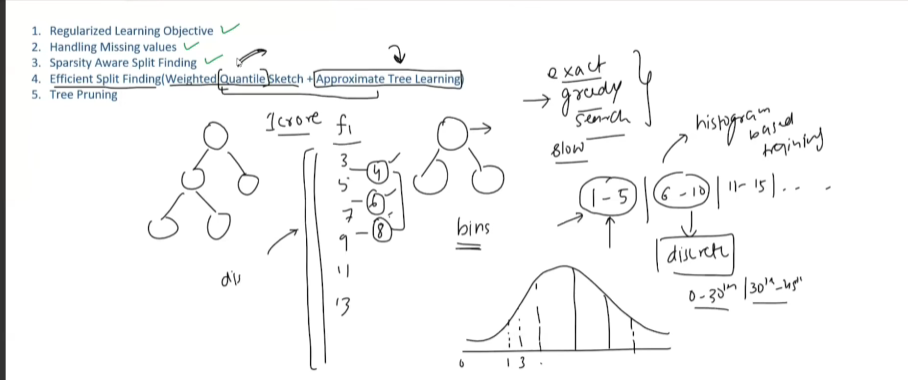

- The benifit of using Quantile/percentile based bins is that it ensures that each bin has approximately the same number of data points, which helps in finding a good split point. This is especially useful when the data is skewed or has outliers.

### 3.5. Tree Pruning

- It is a technique used to reduce the size of the decision tree by restricting the growth of the tree to reduce overfitting.

- In XGBoost we do 2 types of pruning:
    1. **Post Pruning** : Jisme hum tree ko build krne ke baad uske leaf nodes ko check krte hai aur agar koi leaf node ka gain (improvement in loss function) less than a threshold value (gamma) hai to us leaf node ko prune kr dete hai.
    2. **Pre Pruning**: Jisme hum tree ko build krte waqt hi uske leaf nodes ko check krte hai aur agar koi leaf node ka gain (improvement in loss function) less than a threshold value (gamma) hai to us leaf node ko prune kr dete hai.

- XGBoost have parameters for pre-pruning and post-pruning, which are:
    1. **gamma (Minimum Split Loss):**
        - Minimum loss reduction required to perform a further split.
        - Higher gamma makes the algorithm more conservative.

    2. **max_depth:**
        - Maximum depth allowed for each tree.
        - Higher max_depth allows more complex trees and can increase overfitting.

    3. **min_child_weight:**
        - Minimum sum of Hessians required in a child node.
        - If a potential split produces a child with a Hessian sum below this threshold, the split is not allowed.
        - Higher min_child_weight makes the algorithm more conservative.

**Note:** max_depth and min_child_weight act as pre-pruning constraints. gamma controls split acceptance based on loss reduction and also plays a role in tree pruning.



# Some other libraries that implement Gradient Boosting algorithm
- Beside XGBoost, there are other libraries that implement Gradient Boosting algorithm with some additional optimizations and features. Some of them are:
1. LightGBM: Developed by Microsoft, it uses a histogram-based approach and is optimized for speed and memory efficiency.

2. CatBoost: Developed by Yandex, it is designed to handle categorical features natively and is optimized for performance.
